# Analisis Yield, Rework & Defect (Q1-Q14)

Data simulasi buatan sendiri (10 stasiun, 3 model, 2 shift, 75 hari kerja). Notebook ini membaca CSV di `results/` dan menjawab pertanyaan di halaman rancangan. Semua angka dicetak dari data. Hasil membuktikan metode, bukan kondisi pabrik sebenarnya.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "code" / "common.py").exists() or (p / "project" / "code" / "common.py").exists())
ROOT = ROOT / "project" if (ROOT / "project" / "code").exists() else ROOT
sys.path.insert(0, str(ROOT / "code"))
from common import result
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6", "figure.dpi": 100})
pct = lambda v, d=1: f"{v*100:.{d}f}%"
read = lambda n: pd.read_csv(result(n))

## Q13. Kualitas data (validitas)
Berapa persen data tidak valid, dan apakah hasil berubah jika dibuang atau dikoreksi?

In [2]:
rows, dq, sens, cons = read("table_rows.csv"), read("data_quality_summary.csv"), read("sensitivity.csv"), read("consistency_checks.csv")
display(rows); display(dq); display(cons)
print(f"Baris produksi bermasalah: {rows.flagged_rows[0]} dari {rows.raw_rows[0]} ({rows.flagged_pct[0]}%).")
key = sens[sens.metric.isin(["rty", "final_yield", "rework_rate", "scrap_rate", "top_defect_share", "max_shift_gap"])]
display(key)
same = sens.same_conclusion.dropna().astype(bool).all()
print("Kesimpulan kategorikal (stasiun terburuk, defect teratas, stasiun selisih shift, defect tersulit) sama di tiga varian:", same)

,table,raw_rows,clean_rows,flagged_rows,flagged_pct
0,production_daily,4535,4500,112,2.47
1,defect_log,7100,7100,142,2.00
2,rework_log,28566,28566,0,0.00


,table,issue,action,rows,injected,pct_of_table
0,defect_log,defect_code_typo,diperbaiki,142,142,2.00
1,production_daily,blank_shift,diperbaiki,27,27,0.60
2,production_daily,duplicate,dibuang,35,35,0.77
3,production_daily,negative_qty,diperbaiki,22,22,0.49
4,production_daily,ok_ng_over_input,diperbaiki,28,28,0.62


,check,violations
0,ng_qty = jumlah defect_log per kunci,0
1,baris rework_log = qty defect_log per tanggal/...,0
2,rework date_out >= date_in,0
3,result kosong hanya jika date_out kosong,0
4,kunci production_daily unik,0
5,OK + NG = input,0


Baris produksi bermasalah: 112 dari 4535 (2.47%).


,metric,diperbaiki,dibuang,tanpa_cleaning,diff_dibuang,diff_tanpa_cleaning,same_conclusion
0,rty,0.8552681099621628,0.8551971440987254,0.8573052970472678,-0.000071,0.002037,NaN
1,final_yield,0.9827160463764686,0.985093608719477,0.9839228108018458,0.002378,0.001207,NaN
2,rework_rate,0.1535889026291736,0.15573170325830107,0.15216378714951895,0.002143,-0.001425,NaN
3,scrap_rate,0.017199849454271735,0.017744816339209442,0.017127193099866687,0.000545,-0.000073,NaN
7,top_defect_share,0.17783378841979977,0.17851404905566068,0.17503325631870056,0.000680,-0.002801,NaN
10,max_shift_gap,0.010898638368030246,0.010868059782989882,0.01060044965580124,-0.000031,-0.000298,NaN


Kesimpulan kategorikal (stasiun terburuk, defect teratas, stasiun selisih shift, defect tersulit) sama di tiga varian: True


## Q1-Q3. Yield: stasiun, final yield, model

Stasiun FPY terendah: Reflow Soldering (95.99%), menyumbang 26.2% dari seluruh kehilangan RTY.
Rata-rata FPY stasiun 98.45%, tetapi RTY lini 85.53%.
Final yield lini 98.27% vs RTY 85.53%: rework menyelamatkan 12.7 poin.


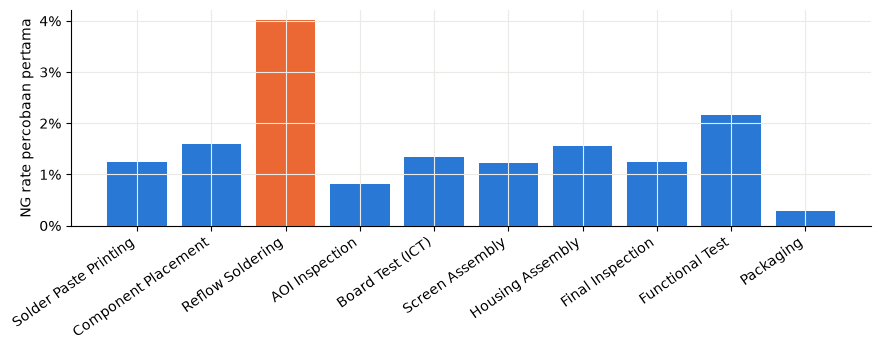

,seq,station,input_qty,ng_qty,fpy,final_yield,rty_loss_share
0,1,Solder Paste Printing,185990,2296,0.9877,0.9996,0.0795
1,2,Component Placement,185888,2980,0.9840,0.9992,0.1034
2,3,Reflow Soldering,185687,7451,0.9599,0.9960,0.2620
3,4,AOI Inspection,184830,1486,0.9920,0.9998,0.0516
4,5,Board Test (ICT),184768,2465,0.9867,0.9983,0.0859
5,6,Screen Assembly,184427,2269,0.9877,0.9954,0.0792
6,7,Housing Assembly,183570,2852,0.9845,0.9988,0.1002
7,8,Final Inspection,183310,2289,0.9875,0.9994,0.0804
8,9,Functional Test,183188,3955,0.9784,0.9961,0.1396
9,10,Packaging,182426,523,0.9971,1.0000,0.0184


,model,rty,ng_qty,units_started,rework_rate
0,Basic,0.8776,8849,68770,0.1287
1,Plus,0.8590,9413,63038,0.1493
2,Pro,0.8233,10304,54182,0.1902


NG rate,1,2,3,4,5,6,7,8,9,10
model,,,,,,,,,,
Basic,0.0104,0.0129,0.0336,0.0071,0.0112,0.0106,0.0128,0.0102,0.0181,0.0026
Plus,0.0125,0.0160,0.0395,0.0075,0.0129,0.0119,0.0146,0.0117,0.0211,0.0027
Pro,0.0146,0.0201,0.0492,0.0099,0.0166,0.0150,0.0201,0.0163,0.0267,0.0033


In [3]:
st, line, mod = read("station.csv"), read("line_kpi.csv").iloc[0], read("model.csv")
w = st.loc[st.fpy.idxmin()]
print(f"Stasiun FPY terendah: {w.station} ({pct(w.fpy,2)}), menyumbang {pct(w.rty_loss_share)} dari seluruh kehilangan RTY.")
print(f"Rata-rata FPY stasiun {pct(line.avg_station_fpy,2)}, tetapi RTY lini {pct(line.rty,2)}.")
print(f"Final yield lini {pct(line.final_yield,2)} vs RTY {pct(line.rty,2)}: rework menyelamatkan {(line.final_yield-line.rty)*100:.1f} poin.")
fig, ax = plt.subplots(figsize=(9, 3.6))
ng = st.ng_qty / st.input_qty
ax.bar(st.station, ng, color=[ORANGE if v == ng.max() else BLUE for v in ng])
ax.set_ylabel("NG rate percobaan pertama"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0)
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
display(st[["seq", "station", "input_qty", "ng_qty", "fpy", "final_yield", "rty_loss_share"]].round(4))
display(mod.round(4))
ms = read("model_station.csv").pivot(index="model", columns="seq", values="fpy")
display((1 - ms).round(4).rename_axis("NG rate", axis=1))

## Q4-Q5. Defect: Pareto dan shift

12 dari 17 jenis defect menyumbang sekitar 80% dari 28,566 NG. Teratas: Solder bridge (17.8%).


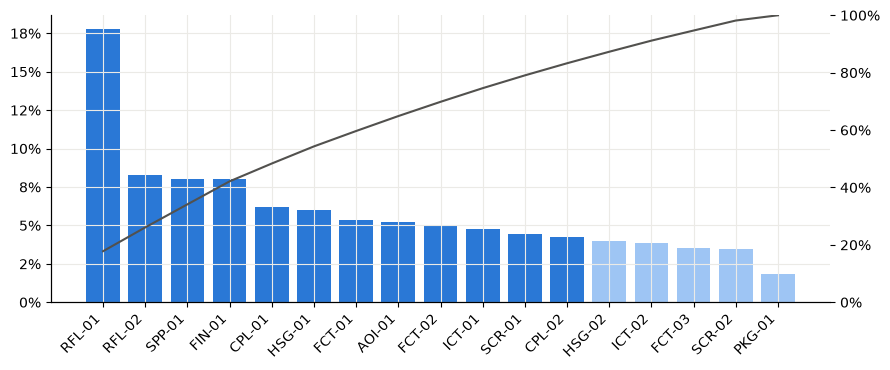

Selisih shift terbesar: Component Placement, NG rate Shift 2 2.15% vs Shift 1 1.06% (rasio 2.03).
Stasiun lain: rasio Shift2/Shift1 antara 0.92 dan 1.10.


,defect_code,defect_name,station,rate_s1,rate_s2,qty_s1,qty_s2
0,CPL-01,Missing component,Component Placement,0.0064,0.0127,598,1176
1,CPL-02,Komponen terbalik,Component Placement,0.0042,0.0088,389,817
2,ICT-01,Short circuit,Board Test (ICT),0.0069,0.0078,639,720
3,AOI-01,Komponen bergeser,AOI Inspection,0.0077,0.0084,711,775


In [4]:
par, ds, ss = read("pareto_line.csv"), read("defect_shift.csv"), read("shift_station.csv")
n80 = int(par.vital_few.sum())
print(f"{n80} dari {len(par)} jenis defect menyumbang sekitar 80% dari {par.qty.sum():,} NG. Teratas: {par.defect_name[0]} ({pct(par.share[0])}).")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(par.defect_code, par.share, color=[BLUE if v else "#9ec5f4" for v in par.vital_few])
ax2 = ax.twinx(); ax2.plot(par.defect_code, par.cum_share, color="#52514e"); ax2.set_ylim(0, 1); ax2.grid(False)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); plt.tight_layout(); plt.show()
g = ss.loc[ss.gap.idxmax()]
print(f"Selisih shift terbesar: {g.station}, NG rate Shift 2 {pct(g.ng_rate_s2,2)} vs Shift 1 {pct(g.ng_rate_s1,2)} (rasio {g.ratio:.2f}).")
print("Stasiun lain: rasio Shift2/Shift1 antara", f"{ss[ss.station != g.station].ratio.min():.2f} dan {ss[ss.station != g.station].ratio.max():.2f}.")
display(ds.head(4).round(4))

## Q6-Q8. Rework: recovery, defect tersulit, lead time dan antrean

Dari 28,566 unit NG: 88.8% berhasil diselamatkan, 3,199 scrap, 12 masih menunggu di akhir periode.
Defect tersulit: Dead pixel (SCR-02), recovery 29.1%, 705 scrap; defect berikutnya Kamera gagal tes 79.5%.


,lead_wd,units,share
0,0,28193,0.986943
1,1,361,0.012637
2,open,12,0.000420


Antrean puncak 78 unit pada 2026-04-10; antrean > 0 pada 15 dari 75 hari; akhir periode 12.


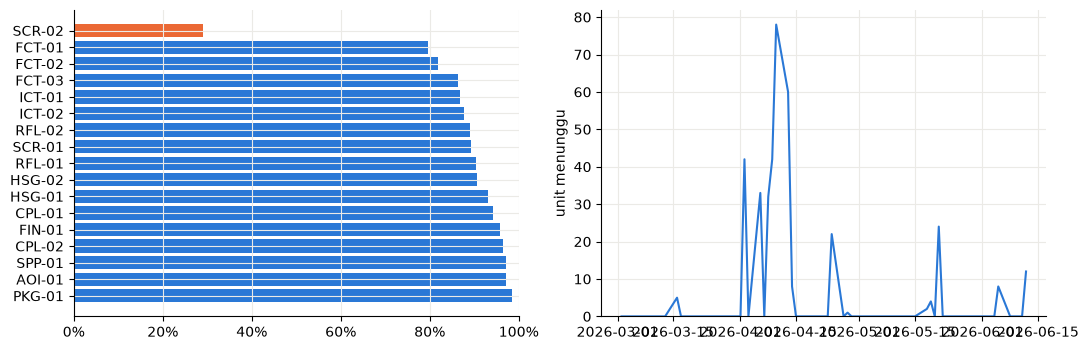

In [5]:
rd, lead, bl = read("rework_defect.csv"), read("rework_lead.csv"), read("backlog_daily.csv")
print(f"Dari {line.ng_events:,.0f} unit NG: {pct(line.recovery_rate)} berhasil diselamatkan, {line.scrap:,.0f} scrap, {line.rework_open:.0f} masih menunggu di akhir periode.")
h = rd.iloc[0]
print(f"Defect tersulit: {h.defect_name} ({h.defect_code}), recovery {pct(h.recovery_rate)}, {h.scrap:,.0f} scrap; defect berikutnya {rd.defect_name[1]} {pct(rd.recovery_rate[1])}.")
display(lead)
print(f"Antrean puncak {bl.backlog.max():.0f} unit pada {bl.date[bl.backlog.idxmax()]}; antrean > 0 pada {(bl.backlog>0).sum()} dari {len(bl)} hari; akhir periode {bl.backlog.iloc[-1]:.0f}.")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].barh(rd.defect_code[::-1], rd.recovery_rate[::-1], color=[BLUE] * (len(rd) - 1) + [ORANGE]); axs[0].set_xlim(0, 1)
axs[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axs[1].plot(pd.to_datetime(bl.date), bl.backlog, color=BLUE); axs[1].set_ylim(0); axs[1].set_ylabel("unit menunggu")
plt.tight_layout(); plt.show()

## Q9-Q10. Tren harian dan lonjakan

Hari lonjakan: 5 (2026-04-06 sampai 2026-04-10), stasiun: Screen Assembly.
Minggu dengan NG per unit tertinggi: minggu 6 (2026-04-06), 0.173 vs median mingguan 0.152.


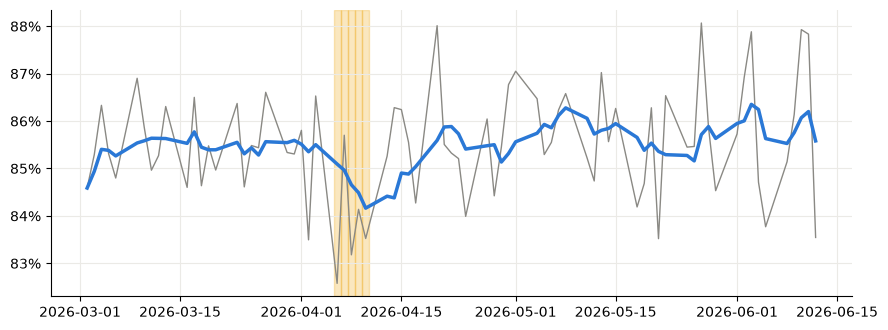

Kelebihan NG per hari lonjakan, station: Screen Assembly menyumbang 98% dari seluruh kelebihan positif (67.4 unit per hari).
Kelebihan NG per hari lonjakan, defect: SCR-01 menyumbang 93% dari seluruh kelebihan positif (67.3 unit per hari).
model: kelebihan positif tersebar Basic 50%, Pro 31%, Plus 19% (semua positif, tidak ada yang melebihi 60%, jadi tidak terpusat).
shift: kelebihan positif tersebar Shift 1 54%, Shift 2 46% (semua positif, tidak ada yang melebihi 60%, jadi tidak terpusat).


In [6]:
dly, spk, drl, wk = read("daily.csv"), read("spike_days.csv"), read("spike_drill.csv"), read("weekly.csv")
days = spk[spk.is_spike]
print(f"Hari lonjakan: {len(days)} ({days.date.iloc[0]} sampai {days.date.iloc[-1]}), stasiun: {', '.join(days.stations.unique())}.")
w6 = wk.loc[wk.ng_per_unit.idxmax()]
print(f"Minggu dengan NG per unit tertinggi: minggu {w6.week} ({w6.week_start}), {w6.ng_per_unit:.3f} vs median mingguan {wk.ng_per_unit.median():.3f}.")
fig, ax = plt.subplots(figsize=(9, 3.4))
d = pd.to_datetime(dly.date)
ax.plot(d, dly.rty, color=GREY, lw=1); ax.plot(d, dly.rty_ma7, color=BLUE, lw=2.5)
for t in pd.to_datetime(days.date): ax.axvspan(t - pd.Timedelta(hours=12), t + pd.Timedelta(hours=12), color="#eda100", alpha=.25)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); plt.tight_layout(); plt.show()
for dim in ("station", "defect"):
    t = drl[drl.dim == dim].iloc[0]
    print(f"Kelebihan NG per hari lonjakan, {dim}: {t.value} menyumbang {pct(t.share_of_excess,0)} dari seluruh kelebihan positif ({t.excess_per_day:.1f} unit per hari).")
for dim in ("model", "shift"):
    t = drl[drl.dim == dim]
    print(f"{dim}: kelebihan positif tersebar " + ", ".join(f"{r.value} {pct(r.share_of_excess,0)}" for r in t.itertuples()) + " (semua positif, tidak ada yang melebihi 60%, jadi tidak terpusat).")
    assert t.share_of_excess.max() < 0.6 and (t.share_of_excess > 0).all()

## Q11-Q12. Dampak (estimated)

In [7]:
imp = read("impact.csv")
imp["scenario"] = imp.target + " -" + (imp.reduction * 100).round().astype(int).astype(str) + "%"
display(imp[["scenario", "rate_old", "rate_new", "units_saved_month", "scrap_avoided_month", "rework_hours_saved_month", "rty_old", "rty_new"]].round(4))
b = imp[(imp.target_type == "station") & (imp.reduction == .3)].iloc[0]
print(f"[estimated, simulated] NG {b.target} turun 30%: sekitar {b.units_saved_month:,.0f} unit per bulan tidak perlu rework, {b.rework_hours_saved_month:,.0f} jam rework, RTY {pct(b.rty_old,2)} menjadi {pct(b.rty_new,2)}.")

,scenario,rate_old,rate_new,units_saved_month,scrap_avoided_month,rework_hours_saved_month,rty_old,rty_new
0,Reflow Soldering -10%,0.0401,0.0361,215.4254,21.5975,61.2001,0.8553,0.8588
1,Reflow Soldering -20%,0.0401,0.0321,430.8507,43.1949,122.4001,0.8553,0.8624
2,Reflow Soldering -30%,0.0401,0.0281,646.2761,64.7924,183.6002,0.8553,0.8660
3,RFL-01 -10%,0.0274,0.0246,146.8743,14.0514,44.0623,0.8553,0.8577
4,RFL-01 -20%,0.0274,0.0219,293.7487,28.1027,88.1246,0.8553,0.8601
5,RFL-01 -30%,0.0274,0.0192,440.6230,42.1541,132.1869,0.8553,0.8626


[estimated, simulated] NG Reflow Soldering turun 30%: sekitar 646 unit per bulan tidak perlu rework, 184 jam rework, RTY 85.53% menjadi 86.60%.

## Q14. Cek silang

In [8]:
cx, ce = read("crosscheck.csv"), read("crosscheck_excel.csv")
print(f"SQL vs pandas: {(cx.status == 'PASS').sum()}/{len(cx)} PASS. SQL vs Excel: {(ce.status == 'PASS').sum()}/{len(ce)} PASS.")
gt = read("ground_truth_check.csv"); display(gt[["id", "fact", "planted", "found", "match"]])

SQL vs pandas: 25/25 PASS. SQL vs Excel: 49/49 PASS.


,id,fact,planted,found,match
0,1,Stasiun paling sering NG,Reflow Soldering / RFL-01,Reflow Soldering (FPY terendah) / RFL-01 68.2%...,True
1,2,Shift 2 lebih tinggi NG di satu stasiun,Component Placement / Shift 2,Component Placement: NG rate Shift 2 2.15% vs ...,True
2,3,Lonjakan defect selama satu minggu,2026-04-06 s.d. 2026-04-10 / Screen Assembly /...,5 hari terdeteksi (2026-04-06 s.d. 2026-04-10)...,True
3,4,Defect sulit di-rework,SCR-02,SCR-02 recovery 29.1%,True
4,5,Data kotor,"duplicate 35, negative_qty 22, ok_ng_over_inpu...","duplicate 35, negative_qty 22, ok_ng_over_inpu...",True
